In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd

con = duckdb.connect()
con.execute("SET TimeZone = 'UTC'")

raw = con.sql("""
    SELECT *
    FROM read_parquet('../data/bronze/station_status/**/*.parquet', hive_partitioning = true)
""").df()

print(f"{len(raw):,} lignes, {raw['source_last_updated'].nunique():,} snapshots")

2,204,492 lignes, 2,093 snapshots


In [2]:
df = raw.drop_duplicates(["station_id", "source_last_updated"])
active = df[(df["is_installed"] == 1) & (df["is_renting"] == 1)].copy()

print(f"Après dédoublonnage : {len(df):,} lignes")
print(f"Stations actives    : {len(active):,} lignes")

Après dédoublonnage : 2,204,492 lignes
Stations actives    : 2,199,672 lignes


Part des observations avec 0 vélo : 13.0%


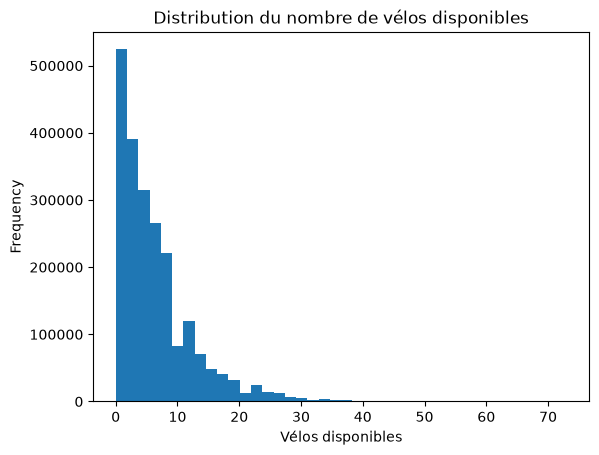

In [3]:
share_empty = (active["num_bikes_available"] == 0).mean()
print(f"Part des observations avec 0 vélo : {share_empty:.1%}")

active["num_bikes_available"].plot.hist(bins=40, title="Distribution du nombre de vélos disponibles")
plt.xlabel("Vélos disponibles")
plt.show()

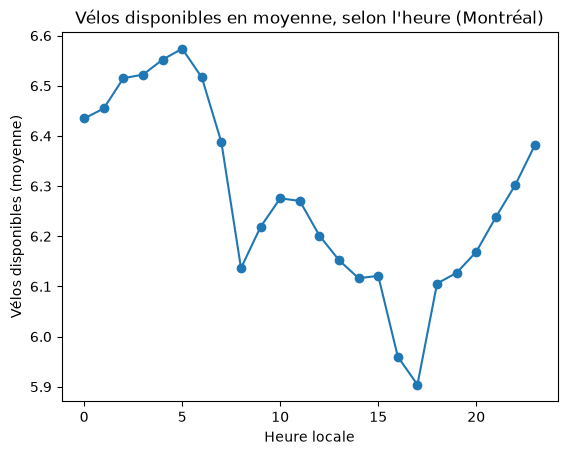

In [4]:
active["local_time"] = active["source_last_updated"].dt.tz_convert("America/Montreal")
active["hour"] = active["local_time"].dt.hour

active.groupby("hour")["num_bikes_available"].mean().plot(
    marker="o", title="Vélos disponibles en moyenne, selon l'heure (Montréal)"
)
plt.xlabel("Heure locale")
plt.ylabel("Vélos disponibles (moyenne)")
plt.show()

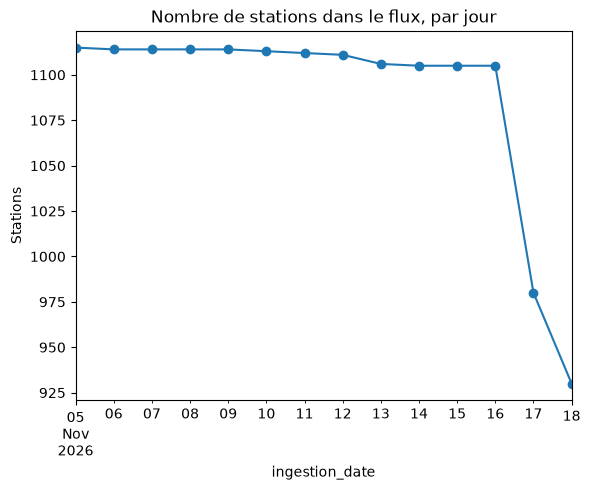

In [5]:
stations_per_day = df.groupby("ingestion_date")["station_id"].nunique()
stations_per_day.plot(marker="o", title="Nombre de stations dans le flux, par jour")
plt.ylabel("Stations")
plt.show()

,horizon_min,paires,MAE_persistance
0,15,2167655,0.398
1,30,2164293,0.642
2,60,2158664,1.016
3,120,2145341,1.572


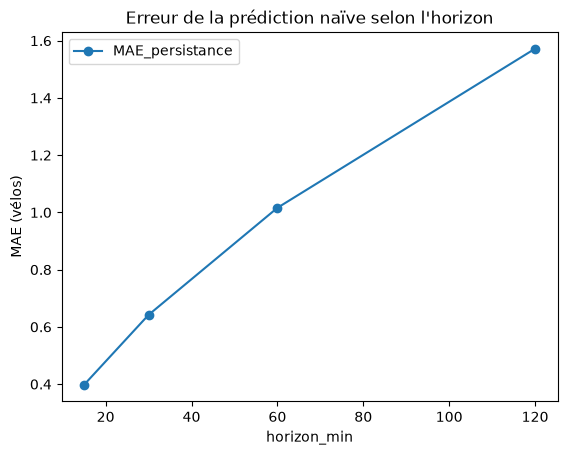

In [6]:
snap = active[["station_id", "source_last_updated", "num_bikes_available"]].rename(
    columns={"source_last_updated": "t"}
)
snap["t"] = snap["t"].astype("datetime64[ns, UTC]")

results = []
for horizon in [15, 30, 60, 120]:
    left = snap.assign(target_time=snap["t"] + pd.Timedelta(minutes=horizon)).sort_values("target_time")
    right = snap.rename(columns={"t": "target_time", "num_bikes_available": "future_bikes"}).sort_values(
        "target_time"
    )
    pairs = pd.merge_asof(
        left, right, on="target_time", by="station_id",
        direction="nearest", tolerance=pd.Timedelta(minutes=3),
    ).dropna(subset=["future_bikes"])
    mae = (pairs["num_bikes_available"] - pairs["future_bikes"]).abs().mean()
    results.append({"horizon_min": horizon, "paires": len(pairs), "MAE_persistance": round(mae, 3)})

baseline = pd.DataFrame(results)
display(baseline)
baseline.plot(x="horizon_min", y="MAE_persistance", marker="o", title="Erreur de la prédiction naïve selon l'horizon")
plt.ylabel("MAE (vélos)")
plt.show()